# 9. The command line

The `penicillium` command generates data sets without writing any Python, and starts the operator console. In a
terminal you would type `penicillium generate ...`; this notebook runs the same commands through
`python -m penicillium` and loads what they write.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

import os
import subprocess
import sys
import tempfile
from pathlib import Path

work = Path(tempfile.mkdtemp())  # the commands run in an empty temporary folder


def penicillium_cli(*args):
    env = {**os.environ, "NO_COLOR": "1"}
    out = subprocess.run(
        [sys.executable, "-m", "penicillium", *args], capture_output=True, text=True, check=True, cwd=work, env=env
    )
    print(out.stdout or out.stderr)


penicillium_cli("--version")
penicillium_cli("generate", "--help")

0.1.0.dev0



usage: penicillium generate [-h] [--n-batches N_BATCHES]
                            [--seed-start SEED_START]
                            [--faults {0,1,2,3,4,5,6,7,8} [{0,1,2,3,4,5,6,7,8} ...]]
                            [--no-disturbances] [--raman]
                            [--noise {none,typical}]
                            [--batch-length BATCH_LENGTH]
                            [--format {parquet,csv}] [--jobs JOBS] --out OUT

options:
  -h, --help            show this help message and exit
  --n-batches N_BATCHES
                        batches per fault type (default 10)
  --seed-start SEED_START
                        seed of the first batch (default 1)
  --faults {0,1,2,3,4,5,6,7,8} [{0,1,2,3,4,5,6,7,8} ...]
                        fault codes to simulate, 0 = none (default 0); see
                        penicillium.Fault
  --no-disturbances     switch off process disturbances
  --raman               also write Raman spectra
  --noise {none,typical}
                  

## Generate a data set

Three batches of each of three fault codes (0 = no fault), with typical measurement noise, in two worker
processes:

In [2]:
penicillium_cli(
    "generate", "--n-batches", "3", "--faults", "0", "1", "3", "--noise", "typical", "--jobs", "2", "--out", "data"
)
out = work / "data"
for p in sorted(out.iterdir()):
    print(f"{p.name:32s} {p.stat().st_size / 1e3:6.0f} kB")

Simulating 9 batches with 2 worker(s) into data/
[1/9] seed 1 NONE: 3602 kg
[2/9] seed 2 NONE: 2440 kg
[3/9] seed 3 NONE: 2224 kg
[4/9] seed 1 AERATION: 1633 kg
[5/9] seed 2 AERATION: 1177 kg
[6/9] seed 3 AERATION: 1271 kg
[7/9] seed 1 SUBSTRATE_FEED: 1985 kg
[8/9] seed 2 SUBSTRATE_FEED: 649 kg
[9/9] seed 3 SUBSTRATE_FEED: 880 kg

batch_00001_fault0.parquet          579 kB
batch_00001_fault1.parquet          575 kB
batch_00001_fault3.parquet          575 kB
batch_00002_fault0.parquet          575 kB
batch_00002_fault1.parquet          574 kB
batch_00002_fault3.parquet          573 kB
batch_00003_fault0.parquet          575 kB
batch_00003_fault1.parquet          574 kB
batch_00003_fault3.parquet          573 kB
metadata.json                         7 kB


One file per batch, named after its seed and fault code, and `metadata.json` with the yield and settings of every
batch. `--n-batches` gives every fault the same seeds (1, 2, 3 here), so the faulty batches are the nominal ones with
the fault added: a paired comparison.

In [3]:
import json

meta = pd.DataFrame(json.loads((out / "metadata.json").read_text())["batches"])
print(meta.pivot(index="seed", columns="fault", values="total_yield_kg").round(0))

df = pd.concat(pd.read_parquet(p) for p in sorted(out.glob("batch_*.parquet")))
print(df.shape, "- columns include", [c for c in df.columns if c.endswith("_true")][:4], "...")

fault  AERATION    NONE  SUBSTRATE_FEED
seed                                   
1        1633.0  3602.0          1985.0
2        1177.0  2440.0           649.0
3        1271.0  2224.0           880.0
(10350, 75) - columns include ['T_true', 'pH_true', 'DO2_true', 'O2_true'] ...


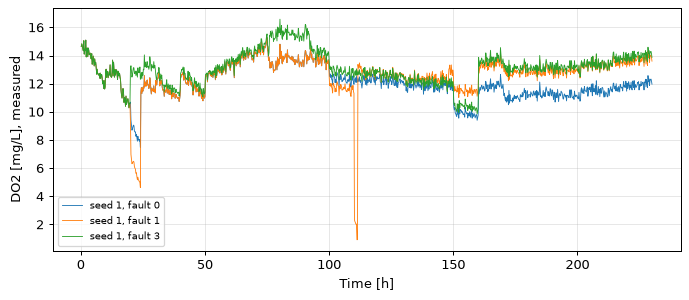

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for fault, g in df[df.seed == 1].groupby("fault"):
    ax.plot(g.index, g.DO2, lw=0.7, label=f"seed 1, fault {fault}")
ax.set(xlabel="Time [h]", ylabel="DO2 [mg/L], measured")
ax.legend(fontsize=8);

Other options: `--raman` writes the spectra, `--no-disturbances`, `--batch-length`, `--seed-start` and
`--format csv`. See [Command line](../cli.md).

## The operator console

```bash
penicillium dcs                 # opens http://localhost:8050/ in your browser
penicillium dcs --port 9000 --no-browser
```

The console is a DCS-style web interface: run a batch in real time or faster, operate the loops and feeds by hand,
acknowledge alarms and send broth samples to the lab. It needs the `dcs` extra; see
[Operator console](../dcs.md).